In [ ]:
#pip install tensorflow

In [39]:
import gymnasium as gym

import numpy as np
import time
import matplotlib.pyplot as plt
import random 
import numpy as np
from collections import defaultdict
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Input
 
 

env=gym.make('CartPole-v1')#,render_mode='human')

(state,_)=env.reset()

In [19]:
def treatState(state):
    state[0]=np.digitize(state[0],pos_space)
    state[1]=np.digitize(state[1],vel_space)
    state[2]=np.digitize(state[2],ang_space)
    state[3]=np.digitize(state[3],ang_vel_space)
    return state

In [110]:
class NN:
    def __init__(
            self,
            input_size=4,
            loss_fct="mse",
            opt_fct="adam",
            metrics=None,
    ):
        """

        :param input_size: number of features given to the NN.
        :param loss_fct: Functions which will calculates the error obtained for the NN predictions.
        :param opt_fct: Optimization function for the NN
        :param metrics: Those are the metrics monitored during the training phase of the neural networks

        """
        if metrics is None:
            metrics = ["mean_squared_error"]
        self.input_size = input_size
        self.loss_fct = loss_fct
        self.opt_fct = opt_fct
        self.metrics = metrics
        # build the neural network
        self.model = Sequential()
        self.model.add(Dense(32, activation="relu", input_shape=(input_size,)))
        self.model.add(Dense(32, activation="relu",))
        #self.model.add(Dense(64, activation="relu",))
        self.model.add(Dense(2, activation="linear"))
        self.model.compile(
            optimizer=self.opt_fct, loss=self.loss_fct, metrics=self.metrics
        )

    def save(self, path: str):
        """
        save the weights of the network
        :param path: filepath where weights are saved
        """
        self.model.save_weights(path)

    def load(self, path: str):
        """
        load the weights of the network
        :param path: filepath where weights are saved
        """
        self.model.load_weights(path)

    def _predict(self, states):
        """
        Return the score for a list of states
        :param states: input list of states
        :return: list of q-values for each state
        """
        input_list = np.array(states)
        predictions = self.model.predict(input_list, verbose=0)
        return predictions

    

In [121]:
class DQN:

    def __init__(self, epsilon, gamma, alpha, num_actions):

   
        self.epsilon = epsilon
        self.gamma = gamma
        self.alpha = alpha
        self.num_actions=num_actions
        random.seed(100)
        self.model=NN()
        self.targetModel=NN()
        
    def getAction(self, state):
        
        if random.random() < self.epsilon:
            return random.randint(0,self.num_actions-1)
        else:
            prediction=np.argmax(self.model._predict([state])[0])
            return prediction
    def episodeRewards(self,episodes): 
        states=[]
        next_states=[]
        for i in range(len(episodes)):
            states.append(episodes[i][0])
            next_states.append(episodes[i][2])
        next_state_predictions=self.targetModel._predict(next_states)  
        targets = self.model._predict(states)  
        for i in range(len(episodes)):
            if i==len(episodes)-1:
                targets[i][episodes[i][1]]=-1
                break

            reward = 1+self.gamma* np.max(next_state_predictions[i])
            targets[i][episodes[i][1]]=reward

        self.model.model.fit(np.array(states), np.array(targets), verbose=0,batch_size=32)
        
        
        

## test

In [122]:
episodeNumber=2000
timeSteps=10000
episodesResults=[]
episodesTestResults=[]
numberOfTest=50
qagent= DQN(1,0.99,0.01,2) #Qlearning(0.1,0.99,0.1,2)
pos_space=np.linspace(-2.4,2.4,10)
vel_space=np.linspace(4,4,10)
ang_space=np.linspace(-0.2095,0.2095,10)
ang_vel_space=np.linspace(-4,4,10)

In [123]:
for episodeIndex in range(0,episodeNumber):
    qagent.epsilon=max(0.99*qagent.epsilon,0.1)
    state,_=env.reset()
    state=treatState(state)
    #print("episode: ",episodeIndex)
    episodeObservation=[]
    for timeIndex in range(timeSteps):
        action=qagent.getAction(tuple(state))
        next_state, reward, terminated, truncated, info =env.step(action)
        next_state=treatState(next_state)
        episodeObservation.append([tuple(state),action,tuple(next_state)])
        #qagent.update(tuple(state),action,tuple(next_state),reward)
        state=next_state
        if (terminated):
            #print("Number of steps :",timeIndex)
            episodesResults.append(timeIndex)
            break
    
    qagent.episodeRewards(episodeObservation)
    if(episodeIndex %100 ==0):
        qagent.model.save("Value.weights.h5")
        qagent.targetModel.load("Value.weights.h5")
    if(episodeIndex %500 ==-1):
        qagent.epsilon=0
        testResultList=[]
        for episodeIndex in range(numberOfTest):
    
            state,_=env.reset()
            state=treatState(state)
            for timeIndex in range(timeSteps):
                action=qagent.getAction(tuple(state))
                next_state, reward, terminated, truncated, info =env.step(action)
                next_state=treatState(next_state)
                state=next_state
                if (terminated):
                    testResultList.append(timeIndex)
                    break

        episodesTestResults.append(sum(testResultList)/numberOfTest)
        qagent.epsilon=0.1
    


env.close() 

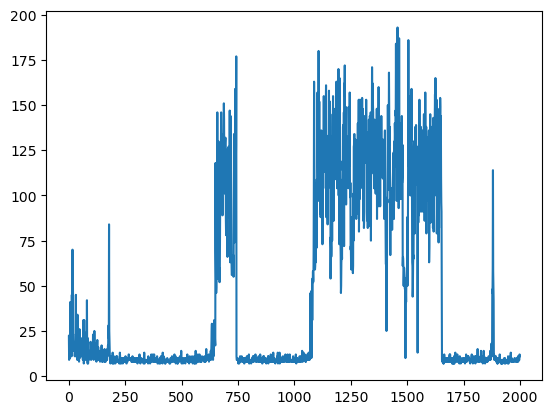

In [124]:
plt.plot(episodesResults)